<a href="https://colab.research.google.com/github/shriyam943/-Nassau-Candy-Distributor/blob/main/Nassau_Candy_Distributor.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.cluster import KMeans

# Load The Dataset

In [2]:
data = pd.read_csv('Nassau Candy Distributor.csv')

# Basic Checks

In [3]:
data.shape

(10194, 18)

In [4]:
data.drop(columns=['Unnamed: 0'], errors='ignore', inplace=True)

In [5]:
data.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Country/Region,City,State/Province,Postal Code,Division,Region,Product ID,Product Name,Sales,Units,Gross Profit,Cost
0,1,US-2021-103800-CHO-MIL-31000,03-01-2024,30-06-2026,Standard Class,103800,United States,Houston,Texas,77095,Chocolate,Interior,CHO-MIL-31000,Wonka Bar - Milk Chocolate,6.50,2,4.22,2.28
1,2,US-2021-112326-CHO-TRI-54000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,7.50,2,4.90,2.60
2,3,US-2021-112326-CHO-NUT-13000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,10.47,3,7.47,3.00
3,4,US-2021-112326-CHO-SCR-58000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,10.80,3,7.50,3.30
4,5,US-2021-141817-CHO-TRI-54000,05-01-2024,05-07-2026,Standard Class,141817,United States,Philadelphia,Pennsylvania,19143,Chocolate,Atlantic,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,11.25,3,7.35,3.90


In [6]:
data.tail()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Country/Region,City,State/Province,Postal Code,Division,Region,Product ID,Product Name,Sales,Units,Gross Profit,Cost
10189,10190,US-2024-143259-CHO-MIL-31000,30-12-2025,26-06-2030,Standard Class,143259,United States,New York City,New York,10009,Chocolate,Atlantic,CHO-MIL-31000,Wonka Bar - Milk Chocolate,9.75,3,6.33,3.42
10190,10191,US-2024-115427-CHO-NUT-13000,30-12-2025,26-06-2030,Standard Class,115427,United States,Fairfield,California,94533,Chocolate,Pacific,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,6.98,2,4.98,2.00
10191,10192,US-2024-156720-CHO-SCR-58000,30-12-2025,26-06-2030,Standard Class,156720,United States,Loveland,Colorado,80538,Chocolate,Pacific,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,10.80,3,7.50,3.30
10192,10193,US-2024-143259-CHO-TRI-54000,30-12-2025,26-06-2030,Standard Class,143259,United States,New York City,New York,10009,Chocolate,Atlantic,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,26.25,7,17.15,9.10
10193,10194,CA-2024-143500-CHO-SCR-58000,30-12-2025,26-06-2030,Standard Class,143500,Canada,Charlottetown,Prince Edward Island,C0A,Chocolate,Atlantic,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,10.80,3,7.50,3.30


In [7]:
data.columns

Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Country/Region', 'City', 'State/Province',
       'Postal Code', 'Division', 'Region', 'Product ID', 'Product Name',
       'Sales', 'Units', 'Gross Profit', 'Cost'],
      dtype='object')

In [8]:
data.dtypes

,0
Row ID,int64
Order ID,object
Order Date,object
Ship Date,object
Ship Mode,object
Customer ID,int64
Country/Region,object
City,object
State/Province,object
Postal Code,object


In [9]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10194 entries, 0 to 10193
Data columns (total 18 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Row ID          10194 non-null  int64  
 1   Order ID        10194 non-null  object 
 2   Order Date      10194 non-null  object 
 3   Ship Date       10194 non-null  object 
 4   Ship Mode       10194 non-null  object 
 5   Customer ID     10194 non-null  int64  
 6   Country/Region  10194 non-null  object 
 7   City            10194 non-null  object 
 8   State/Province  10194 non-null  object 
 9   Postal Code     10194 non-null  object 
 10  Division        10194 non-null  object 
 11  Region          10194 non-null  object 
 12  Product ID      10194 non-null  object 
 13  Product Name    10194 non-null  object 
 14  Sales           10194 non-null  float64
 15  Units           10194 non-null  int64  
 16  Gross Profit    10194 non-null  float64
 17  Cost            10194 non-null 

# Exploratory Data Analysis

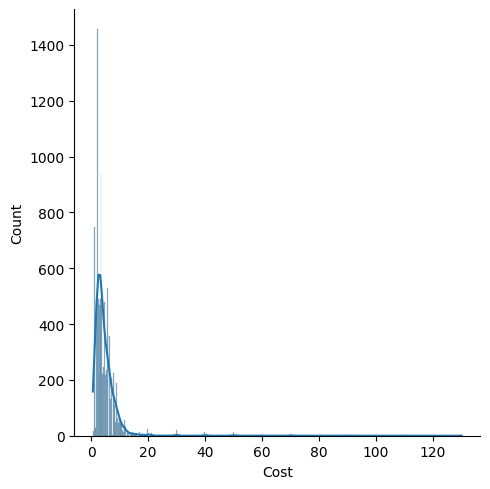

In [10]:
sns.displot(
    x=data['Cost'],
    kde=True
)

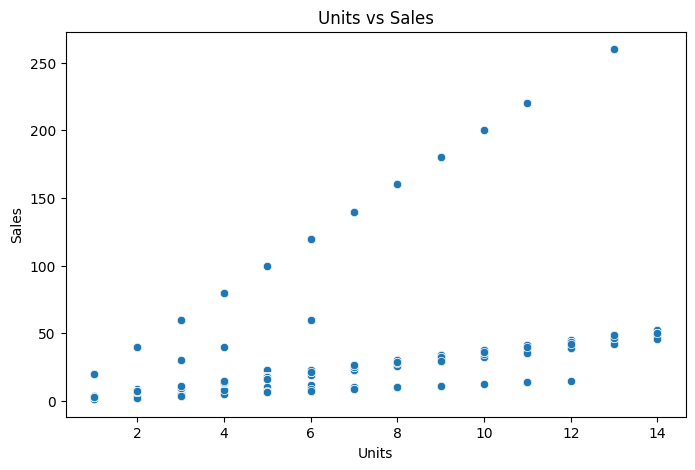

In [11]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    x=data['Units'],
    y=data['Sales']
)

plt.title('Units vs Sales')
plt.show()

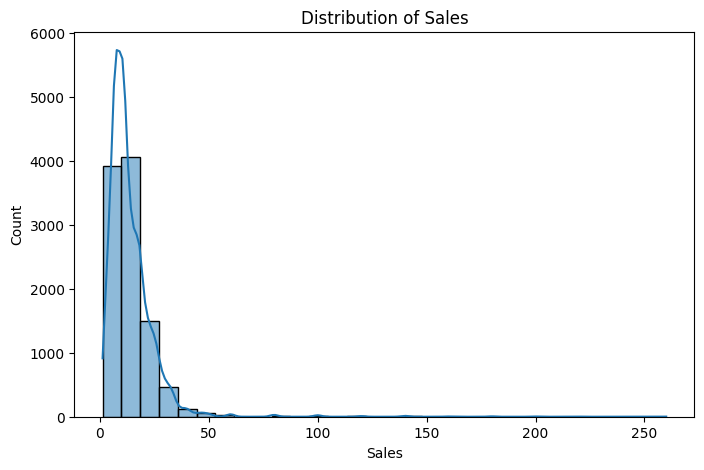

In [12]:
plt.figure(figsize=(8,5))

sns.histplot(
    data=data,
    x='Sales',
    bins=30,
    kde=True
)

plt.title('Distribution of Sales')
plt.show()

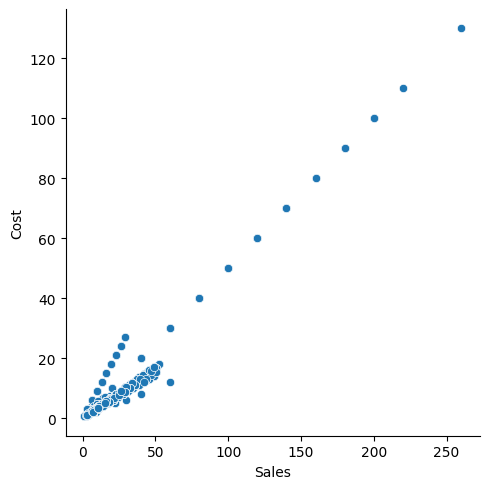

In [13]:
sns.relplot(
    x='Sales',
    y='Cost',
    data=data
)

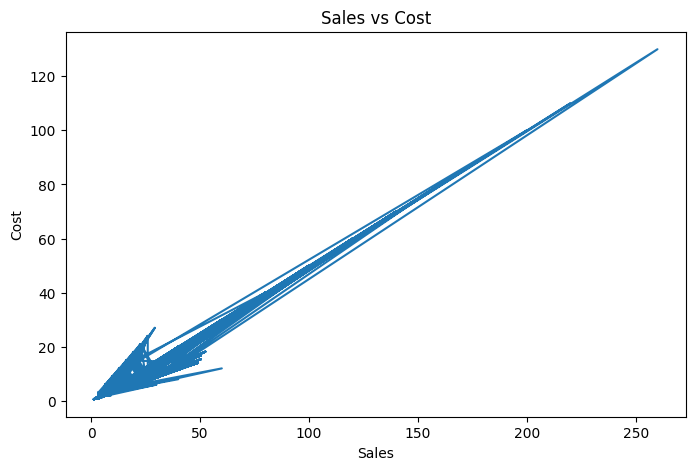

In [14]:
plt.figure(figsize=(8,5))

plt.plot(data['Sales'], data['Cost'])

plt.xlabel('Sales')
plt.ylabel('Cost')
plt.title('Sales vs Cost')

plt.show()


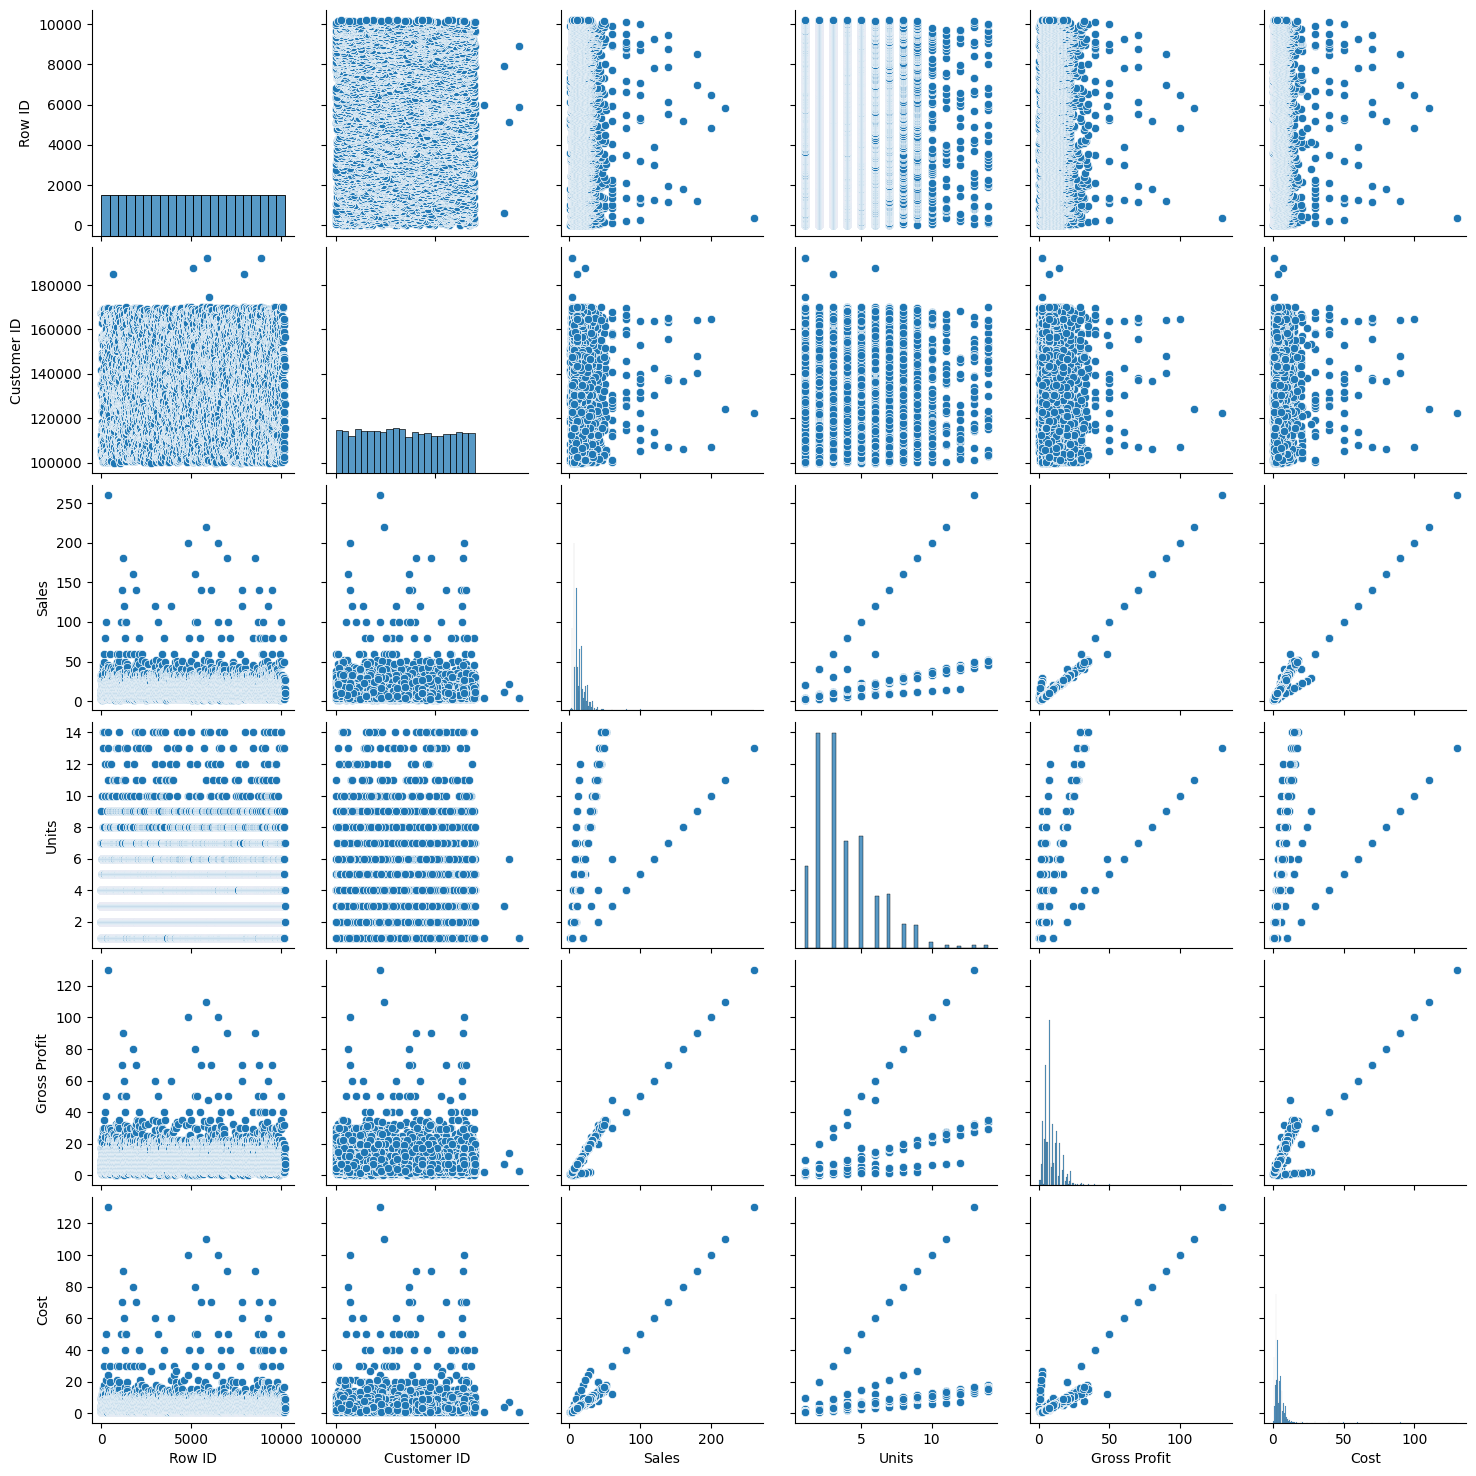

In [15]:
sns.pairplot(data)
plt.show()

# Data Preprocessing and Feature Engineering

In [16]:
data.isnull().sum()

,0
Row ID,0
Order ID,0
Order Date,0
Ship Date,0
Ship Mode,0
Customer ID,0
Country/Region,0
City,0
State/Province,0
Postal Code,0


<Axes: xlabel='Row ID'>

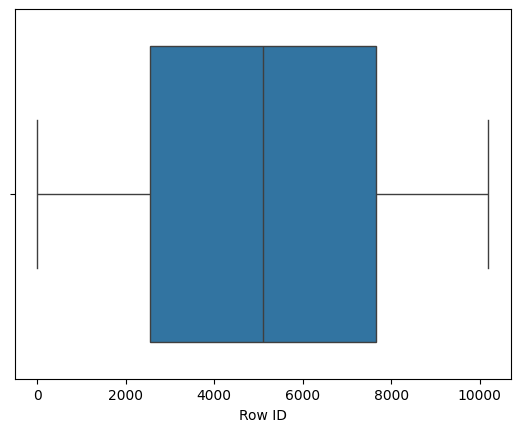

In [17]:
sns.boxplot(x='Row ID',data=data)

<Axes: xlabel='Order ID'>

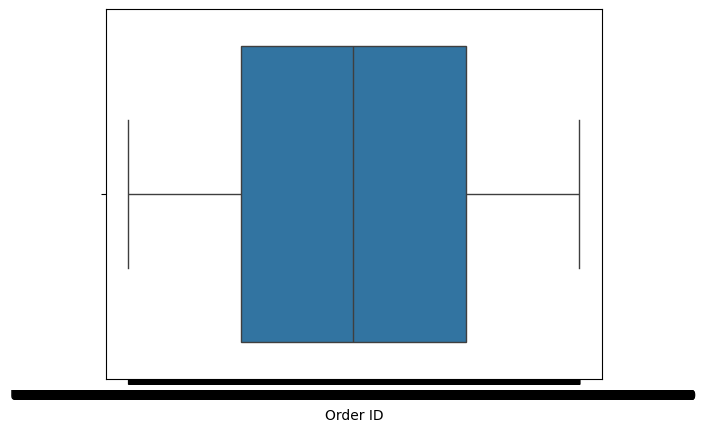

In [18]:
sns.boxplot(x='Order ID',data=data)

<Axes: xlabel='Sales'>

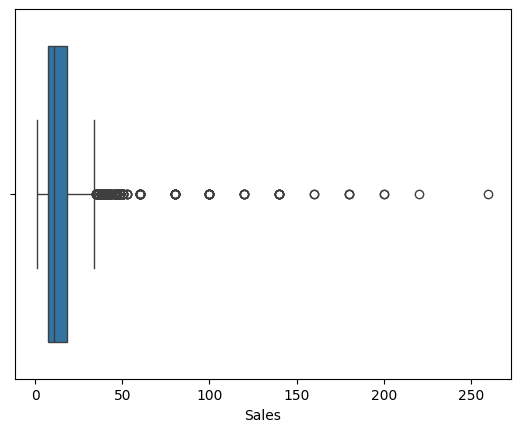

In [19]:
sns.boxplot(x='Sales',data=data)

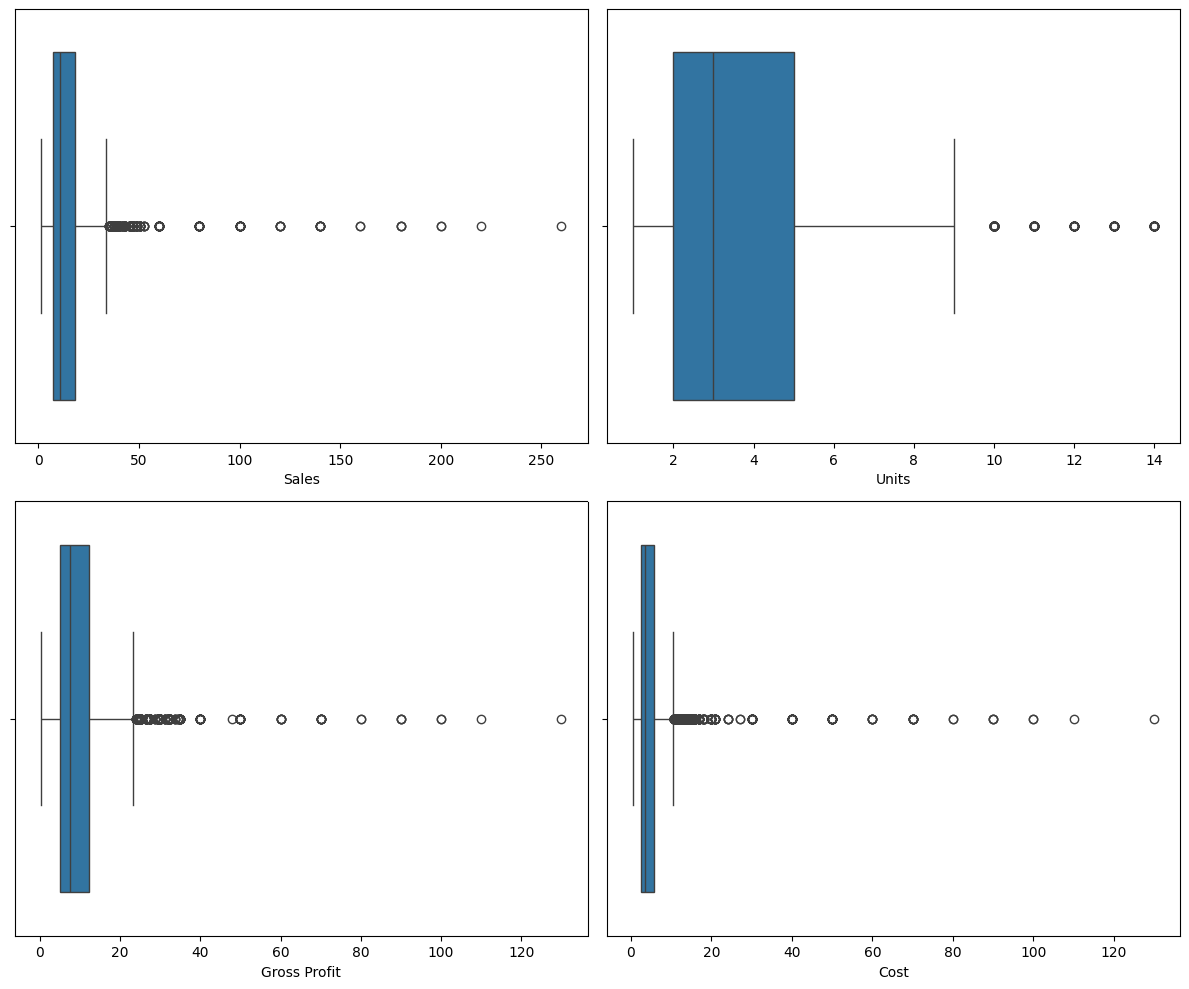

In [20]:
plt.figure(figsize=(12,10))

plotnumber = 1

numerical_cols = [
    'Sales',
    'Units',
    'Gross Profit',
    'Cost'
]

for col in numerical_cols:

    plt.subplot(2,2,plotnumber)

    sns.boxplot(x=data[col])

    plt.xlabel(col, fontsize=10)

    plotnumber += 1

plt.tight_layout()
plt.show()

In [21]:
q1 = data['Sales'].quantile(0.25)
q1

np.float64(7.2)

In [22]:
q3=data['Sales'].quantile(0.75)
q3

np.float64(18.0)

In [23]:
iqr=q3-q1
iqr

np.float64(10.8)

In [24]:
lower = q1 - 1.5 * iqr
lower

np.float64(-9.000000000000004)

In [25]:
upper = q3 + 1.5 * iqr
upper

np.float64(34.2)

In [26]:
data.loc[data['Sales']<lower]

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Country/Region,City,State/Province,Postal Code,Division,Region,Product ID,Product Name,Sales,Units,Gross Profit,Cost


In [27]:
data.loc[data['Sales']<upper]

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Country/Region,City,State/Province,Postal Code,Division,Region,Product ID,Product Name,Sales,Units,Gross Profit,Cost
0,1,US-2021-103800-CHO-MIL-31000,03-01-2024,30-06-2026,Standard Class,103800,United States,Houston,Texas,77095,Chocolate,Interior,CHO-MIL-31000,Wonka Bar - Milk Chocolate,6.50,2,4.22,2.28
1,2,US-2021-112326-CHO-TRI-54000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,7.50,2,4.90,2.60
2,3,US-2021-112326-CHO-NUT-13000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,10.47,3,7.47,3.00
3,4,US-2021-112326-CHO-SCR-58000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,10.80,3,7.50,3.30
4,5,US-2021-141817-CHO-TRI-54000,05-01-2024,05-07-2026,Standard Class,141817,United States,Philadelphia,Pennsylvania,19143,Chocolate,Atlantic,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,11.25,3,7.35,3.90
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10189,10190,US-2024-143259-CHO-MIL-31000,30-12-2025,26-06-2030,Standard Class,143259,United States,New York City,New York,10009,Chocolate,Atlantic,CHO-MIL-31000,Wonka Bar - Milk Chocolate,9.75,3,6.33,3.42
10190,10191,US-2024-115427-CHO-NUT-13000,30-12-2025,26-06-2030,Standard Class,115427,United States,Fairfield,California,94533,Chocolate,Pacific,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,6.98,2,4.98,2.00
10191,10192,US-2024-156720-CHO-SCR-58000,30-12-2025,26-06-2030,Standard Class,156720,United States,Loveland,Colorado,80538,Chocolate,Pacific,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,10.80,3,7.50,3.30
10192,10193,US-2024-143259-CHO-TRI-54000,30-12-2025,26-06-2030,Standard Class,143259,United States,New York City,New York,10009,Chocolate,Atlantic,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,26.25,7,17.15,9.10


In [28]:
len(data.loc[data['Sales']>upper])

245

In [29]:
len(data)

10194

In [30]:
data.loc[data['Sales']<upper]

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Country/Region,City,State/Province,Postal Code,Division,Region,Product ID,Product Name,Sales,Units,Gross Profit,Cost
0,1,US-2021-103800-CHO-MIL-31000,03-01-2024,30-06-2026,Standard Class,103800,United States,Houston,Texas,77095,Chocolate,Interior,CHO-MIL-31000,Wonka Bar - Milk Chocolate,6.50,2,4.22,2.28
1,2,US-2021-112326-CHO-TRI-54000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,7.50,2,4.90,2.60
2,3,US-2021-112326-CHO-NUT-13000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,10.47,3,7.47,3.00
3,4,US-2021-112326-CHO-SCR-58000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,10.80,3,7.50,3.30
4,5,US-2021-141817-CHO-TRI-54000,05-01-2024,05-07-2026,Standard Class,141817,United States,Philadelphia,Pennsylvania,19143,Chocolate,Atlantic,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,11.25,3,7.35,3.90
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10189,10190,US-2024-143259-CHO-MIL-31000,30-12-2025,26-06-2030,Standard Class,143259,United States,New York City,New York,10009,Chocolate,Atlantic,CHO-MIL-31000,Wonka Bar - Milk Chocolate,9.75,3,6.33,3.42
10190,10191,US-2024-115427-CHO-NUT-13000,30-12-2025,26-06-2030,Standard Class,115427,United States,Fairfield,California,94533,Chocolate,Pacific,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,6.98,2,4.98,2.00
10191,10192,US-2024-156720-CHO-SCR-58000,30-12-2025,26-06-2030,Standard Class,156720,United States,Loveland,Colorado,80538,Chocolate,Pacific,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,10.80,3,7.50,3.30
10192,10193,US-2024-143259-CHO-TRI-54000,30-12-2025,26-06-2030,Standard Class,143259,United States,New York City,New York,10009,Chocolate,Atlantic,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,26.25,7,17.15,9.10


In [31]:
data['Sales'].median()

10.8

<Axes: xlabel='Sales'>

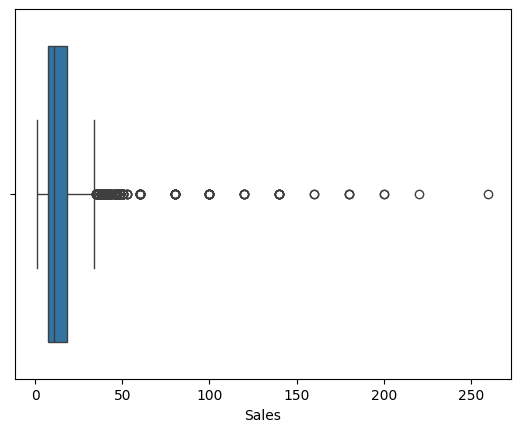

In [32]:
sns.boxplot(x='Sales',data=data)

In [33]:
data.loc[data['Sales']>upper,'Sales']=data['Sales'].median()

<Axes: xlabel='Sales'>

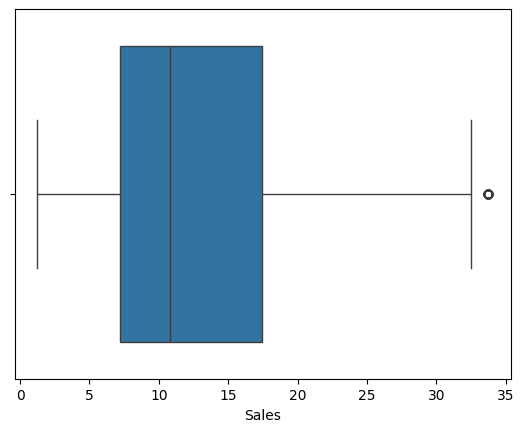

In [34]:
sns.boxplot(x='Sales',data=data)

<Axes: xlabel='Units'>

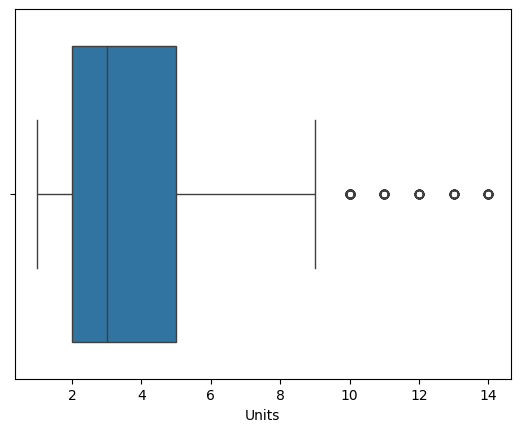

In [35]:
sns.boxplot(x='Units',data=data)

In [36]:
q1=data['Units'].quantile(0.25)
q1

np.float64(2.0)

In [37]:
q3=data['Units'].quantile(0.75)
q3

np.float64(5.0)

In [38]:
iqr=q3-q1
iqr

np.float64(3.0)

In [39]:
lower = q1 - 1.5 * iqr
lower

np.float64(-2.5)

In [40]:
upper = q3 + 1.5 * iqr
upper

np.float64(9.5)

In [41]:
data.loc[data['Units']<lower]

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Country/Region,City,State/Province,Postal Code,Division,Region,Product ID,Product Name,Sales,Units,Gross Profit,Cost


In [42]:
data.loc[data['Units']<upper]

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Country/Region,City,State/Province,Postal Code,Division,Region,Product ID,Product Name,Sales,Units,Gross Profit,Cost
0,1,US-2021-103800-CHO-MIL-31000,03-01-2024,30-06-2026,Standard Class,103800,United States,Houston,Texas,77095,Chocolate,Interior,CHO-MIL-31000,Wonka Bar - Milk Chocolate,6.50,2,4.22,2.28
1,2,US-2021-112326-CHO-TRI-54000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,7.50,2,4.90,2.60
2,3,US-2021-112326-CHO-NUT-13000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,10.47,3,7.47,3.00
3,4,US-2021-112326-CHO-SCR-58000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,10.80,3,7.50,3.30
4,5,US-2021-141817-CHO-TRI-54000,05-01-2024,05-07-2026,Standard Class,141817,United States,Philadelphia,Pennsylvania,19143,Chocolate,Atlantic,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,11.25,3,7.35,3.90
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10189,10190,US-2024-143259-CHO-MIL-31000,30-12-2025,26-06-2030,Standard Class,143259,United States,New York City,New York,10009,Chocolate,Atlantic,CHO-MIL-31000,Wonka Bar - Milk Chocolate,9.75,3,6.33,3.42
10190,10191,US-2024-115427-CHO-NUT-13000,30-12-2025,26-06-2030,Standard Class,115427,United States,Fairfield,California,94533,Chocolate,Pacific,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,6.98,2,4.98,2.00
10191,10192,US-2024-156720-CHO-SCR-58000,30-12-2025,26-06-2030,Standard Class,156720,United States,Loveland,Colorado,80538,Chocolate,Pacific,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,10.80,3,7.50,3.30
10192,10193,US-2024-143259-CHO-TRI-54000,30-12-2025,26-06-2030,Standard Class,143259,United States,New York City,New York,10009,Chocolate,Atlantic,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,26.25,7,17.15,9.10


In [43]:
len(data.loc[data['Units']>upper])

175

In [44]:
(len(data.loc[data['Units']>upper])/len(data))*100

1.7166960957425936

In [45]:
data['Units'].median()

3.0

<Axes: xlabel='Units'>

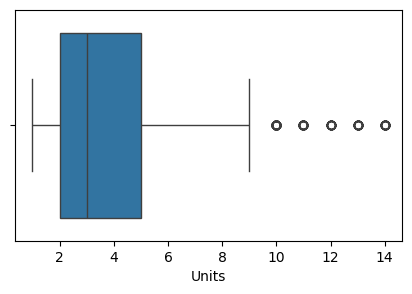

In [46]:
plt.figure(figsize=(5,3))
sns.boxplot(x=data['Units'])

In [47]:
data.loc[data['Units']>upper,'Units']=data['Units'].median()

<Axes: xlabel='Units'>

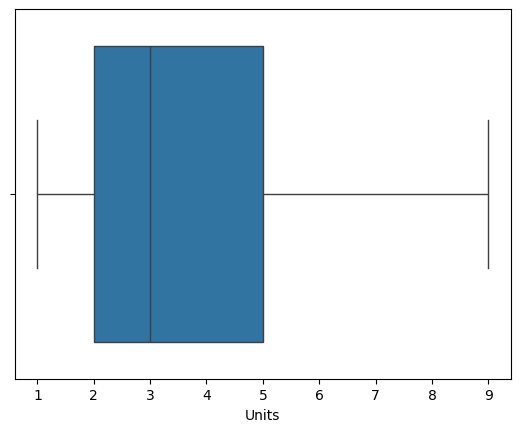

In [48]:
sns.boxplot(x='Units',data=data)

<Axes: xlabel='Gross Profit'>

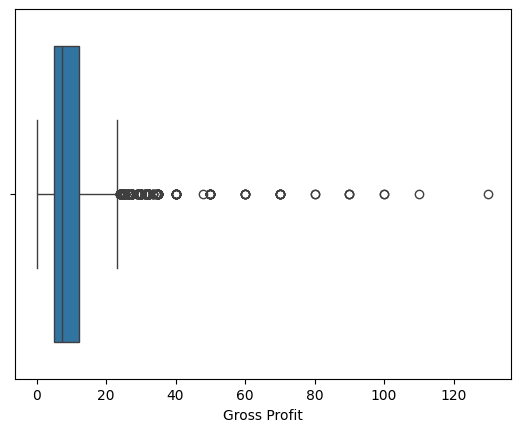

In [49]:
sns.boxplot(x='Gross Profit',data=data)

In [50]:
q1=data['Gross Profit'].quantile(0.25)
q1

np.float64(4.9)

In [51]:
q3=data['Gross Profit'].quantile(0.75)
q3

np.float64(12.25)

In [52]:
iqr=q3-q1
iqr

np.float64(7.35)

In [53]:
lower = q1 - 1.5 * iqr
lower

np.float64(-6.124999999999998)

In [54]:
upper = q3 + 1.5 * iqr
upper

np.float64(23.275)

In [55]:
data.loc[data['Gross Profit']<lower]

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Country/Region,City,State/Province,Postal Code,Division,Region,Product ID,Product Name,Sales,Units,Gross Profit,Cost


In [56]:
data.loc[data['Gross Profit']<upper]

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Country/Region,City,State/Province,Postal Code,Division,Region,Product ID,Product Name,Sales,Units,Gross Profit,Cost
0,1,US-2021-103800-CHO-MIL-31000,03-01-2024,30-06-2026,Standard Class,103800,United States,Houston,Texas,77095,Chocolate,Interior,CHO-MIL-31000,Wonka Bar - Milk Chocolate,6.50,2,4.22,2.28
1,2,US-2021-112326-CHO-TRI-54000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,7.50,2,4.90,2.60
2,3,US-2021-112326-CHO-NUT-13000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,10.47,3,7.47,3.00
3,4,US-2021-112326-CHO-SCR-58000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,10.80,3,7.50,3.30
4,5,US-2021-141817-CHO-TRI-54000,05-01-2024,05-07-2026,Standard Class,141817,United States,Philadelphia,Pennsylvania,19143,Chocolate,Atlantic,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,11.25,3,7.35,3.90
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10189,10190,US-2024-143259-CHO-MIL-31000,30-12-2025,26-06-2030,Standard Class,143259,United States,New York City,New York,10009,Chocolate,Atlantic,CHO-MIL-31000,Wonka Bar - Milk Chocolate,9.75,3,6.33,3.42
10190,10191,US-2024-115427-CHO-NUT-13000,30-12-2025,26-06-2030,Standard Class,115427,United States,Fairfield,California,94533,Chocolate,Pacific,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,6.98,2,4.98,2.00
10191,10192,US-2024-156720-CHO-SCR-58000,30-12-2025,26-06-2030,Standard Class,156720,United States,Loveland,Colorado,80538,Chocolate,Pacific,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,10.80,3,7.50,3.30
10192,10193,US-2024-143259-CHO-TRI-54000,30-12-2025,26-06-2030,Standard Class,143259,United States,New York City,New York,10009,Chocolate,Atlantic,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,26.25,7,17.15,9.10


In [57]:
len(data.loc[data['Gross Profit']>upper])

217

In [58]:
(len(data.loc[data['Gross Profit']>upper])/len(data))*100

2.1287031587208163

In [59]:
data['Gross Profit'].median()

7.47

<Axes: xlabel='Gross Profit'>

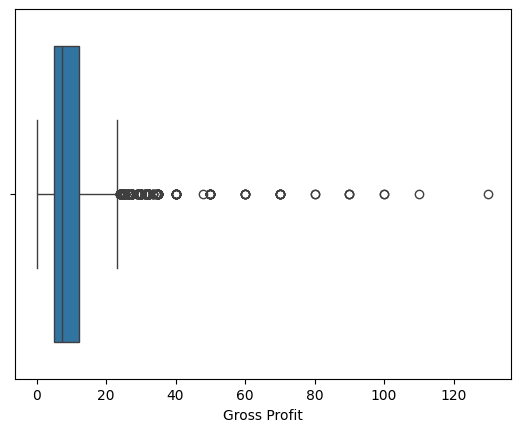

In [60]:
sns.boxplot(x='Gross Profit',data=data)

In [61]:
data.loc[data['Gross Profit']>upper,'Gross Profit']=data['Gross Profit'].median()

<Axes: xlabel='Gross Profit'>

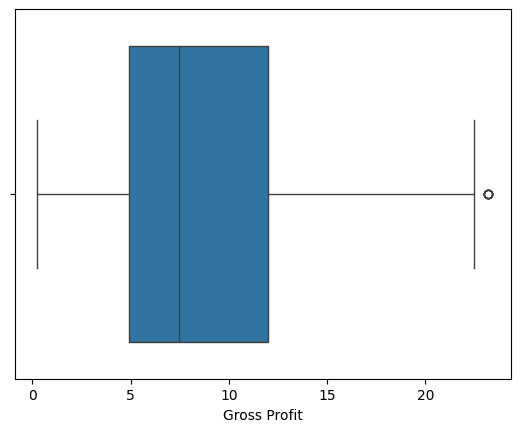

In [62]:
sns.boxplot(x='Gross Profit',data=data)

In [63]:
data.columns

Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Country/Region', 'City', 'State/Province',
       'Postal Code', 'Division', 'Region', 'Product ID', 'Product Name',
       'Sales', 'Units', 'Gross Profit', 'Cost'],
      dtype='object')

<Axes: xlabel='Cost'>

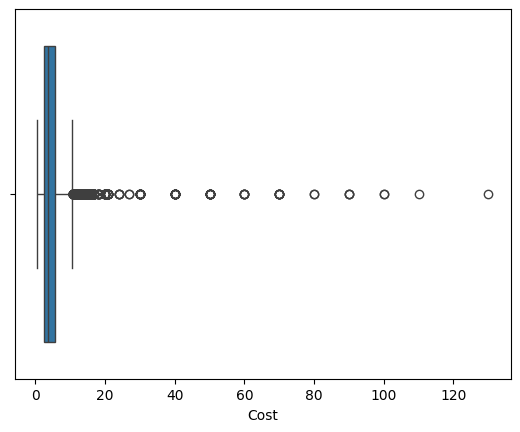

In [64]:
sns.boxplot(x='Cost',data=data)

In [65]:
q1=data['Cost'].quantile(0.25)
q1

np.float64(2.4)

In [66]:
q3=data['Cost'].quantile(0.75)
q3

np.float64(5.7)

In [67]:
iqr = q3-q1
iqr

np.float64(3.3000000000000003)

In [68]:
lower = q1-1.5*iqr
lower

np.float64(-2.5500000000000003)

In [69]:
upper = q3+1.5*iqr
upper

np.float64(10.65)

In [70]:
data.loc[data['Cost']<lower]

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Country/Region,City,State/Province,Postal Code,Division,Region,Product ID,Product Name,Sales,Units,Gross Profit,Cost


In [71]:
data.loc[data['Cost']<upper]

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Country/Region,City,State/Province,Postal Code,Division,Region,Product ID,Product Name,Sales,Units,Gross Profit,Cost
0,1,US-2021-103800-CHO-MIL-31000,03-01-2024,30-06-2026,Standard Class,103800,United States,Houston,Texas,77095,Chocolate,Interior,CHO-MIL-31000,Wonka Bar - Milk Chocolate,6.50,2,4.22,2.28
1,2,US-2021-112326-CHO-TRI-54000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,7.50,2,4.90,2.60
2,3,US-2021-112326-CHO-NUT-13000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,10.47,3,7.47,3.00
3,4,US-2021-112326-CHO-SCR-58000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,10.80,3,7.50,3.30
4,5,US-2021-141817-CHO-TRI-54000,05-01-2024,05-07-2026,Standard Class,141817,United States,Philadelphia,Pennsylvania,19143,Chocolate,Atlantic,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,11.25,3,7.35,3.90
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10189,10190,US-2024-143259-CHO-MIL-31000,30-12-2025,26-06-2030,Standard Class,143259,United States,New York City,New York,10009,Chocolate,Atlantic,CHO-MIL-31000,Wonka Bar - Milk Chocolate,9.75,3,6.33,3.42
10190,10191,US-2024-115427-CHO-NUT-13000,30-12-2025,26-06-2030,Standard Class,115427,United States,Fairfield,California,94533,Chocolate,Pacific,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,6.98,2,4.98,2.00
10191,10192,US-2024-156720-CHO-SCR-58000,30-12-2025,26-06-2030,Standard Class,156720,United States,Loveland,Colorado,80538,Chocolate,Pacific,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,10.80,3,7.50,3.30
10192,10193,US-2024-143259-CHO-TRI-54000,30-12-2025,26-06-2030,Standard Class,143259,United States,New York City,New York,10009,Chocolate,Atlantic,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,26.25,7,17.15,9.10


In [72]:
data.loc[data['Cost']>upper]

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Country/Region,City,State/Province,Postal Code,Division,Region,Product ID,Product Name,Sales,Units,Gross Profit,Cost
40,41,US-2021-146591-CHO-FUD-51000,19-01-2024,13-07-2026,First Class,146591,United States,Scottsdale,Arizona,85254,Chocolate,Pacific,CHO-FUD-51000,Wonka Bar - Fudge Mallows,10.80,3,7.47,12.00
65,66,CA-2021-115238-CHO-MIL-31000,21-01-2024,17-07-2026,Standard Class,115238,Canada,Toronto,Ontario,M7A,Chocolate,Atlantic,CHO-MIL-31000,Wonka Bar - Milk Chocolate,32.50,3,21.10,11.40
76,77,US-2021-155502-CHO-MIL-31000,26-01-2024,24-07-2026,Standard Class,155502,United States,Alexandria,Virginia,22304,Chocolate,Gulf,CHO-MIL-31000,Wonka Bar - Milk Chocolate,10.80,3,7.47,14.82
92,93,US-2021-107181-OTH-KAZ-38000,04-02-2024,01-08-2026,Standard Class,107181,United States,San Diego,California,92024,Other,Pacific,OTH-KAZ-38000,Kazookles,13.00,4,1.00,12.00
117,118,US-2021-154165-CHO-MIL-31000,17-02-2024,17-08-2026,Standard Class,154165,United States,Chicago,Illinois,60653,Chocolate,Interior,CHO-MIL-31000,Wonka Bar - Milk Chocolate,10.80,3,7.47,15.96
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10000,10001,US-2024-137463-OTH-LIC-15000,16-12-2025,12-06-2030,Second Class,137463,United States,Sunnyvale,California,94086,Other,Pacific,OTH-LIC-15000,Lickable Wallpaper,10.80,5,7.47,50.00
10009,10010,US-2024-137463-OTH-KAZ-38000,16-12-2025,12-06-2030,Second Class,137463,United States,Sunnyvale,California,94086,Other,Pacific,OTH-KAZ-38000,Kazookles,16.25,5,1.25,15.00
10027,10028,US-2024-115602-CHO-FUD-51000,18-12-2025,16-06-2030,Standard Class,115602,United States,New York City,New York,10009,Chocolate,Atlantic,CHO-FUD-51000,Wonka Bar - Fudge Mallows,10.80,3,7.47,15.60
10101,10102,US-2024-117443-OTH-LIC-15000,23-12-2025,17-06-2030,Second Class,117443,United States,Rockford,Illinois,61107,Other,Interior,OTH-LIC-15000,Lickable Wallpaper,10.80,4,7.47,40.00


In [73]:
(len(data)-len(data.loc[data['Cost']>upper]))/len(data)*100


96.10555228565823

In [74]:
data['Cost'].median()

3.6

In [75]:
data.loc[data['Cost']>upper,'Cost']=data['Cost'].median()

<Axes: xlabel='Cost'>

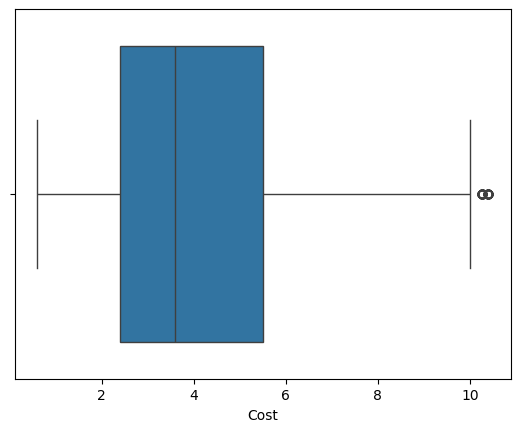

In [76]:
sns.boxplot(x=data['Cost'])

# Heatmap

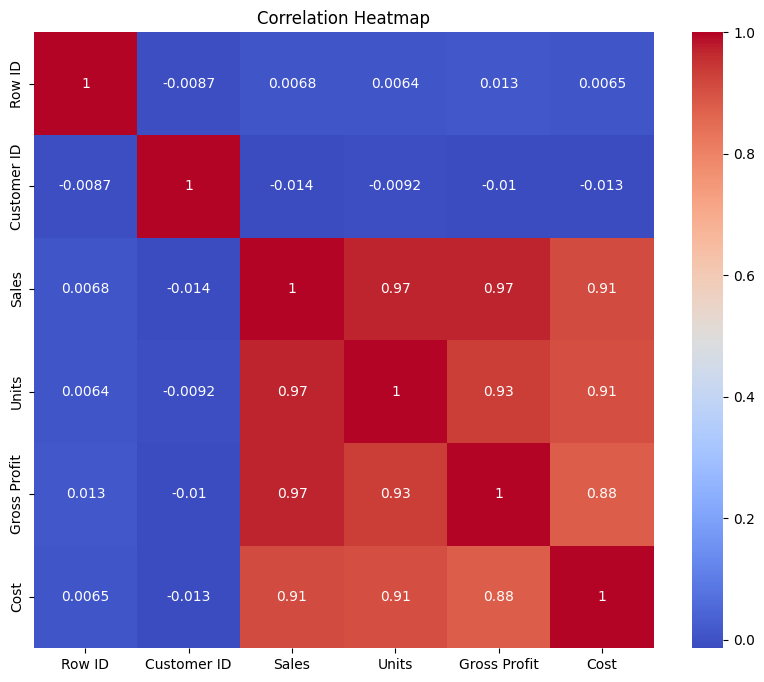

In [77]:
plt.figure(figsize=(10,8))

sns.heatmap(
    data.select_dtypes(include=['int64', 'float64']).corr(),
    annot=True,
    cmap='coolwarm'
)

plt.title('Correlation Heatmap')
plt.show()

Model building

In [78]:
data.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Country/Region,City,State/Province,Postal Code,Division,Region,Product ID,Product Name,Sales,Units,Gross Profit,Cost
0,1,US-2021-103800-CHO-MIL-31000,03-01-2024,30-06-2026,Standard Class,103800,United States,Houston,Texas,77095,Chocolate,Interior,CHO-MIL-31000,Wonka Bar - Milk Chocolate,6.50,2,4.22,2.28
1,2,US-2021-112326-CHO-TRI-54000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,7.50,2,4.90,2.60
2,3,US-2021-112326-CHO-NUT-13000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,10.47,3,7.47,3.00
3,4,US-2021-112326-CHO-SCR-58000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,10.80,3,7.50,3.30
4,5,US-2021-141817-CHO-TRI-54000,05-01-2024,05-07-2026,Standard Class,141817,United States,Philadelphia,Pennsylvania,19143,Chocolate,Atlantic,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,11.25,3,7.35,3.90


In [79]:
data['Order Date'] = pd.to_datetime(
    data['Order Date'],
    dayfirst=True
)

data['Ship Date'] = pd.to_datetime(
    data['Ship Date'],
    dayfirst=True
)

data['Lead Time'] = (
    data['Ship Date'] -
    data['Order Date']
).dt.days

In [80]:
X = data.drop(
    ['Order Date','Ship Date'],
    axis=1
)
X


,Row ID,Order ID,Ship Mode,Customer ID,Country/Region,City,State/Province,Postal Code,Division,Region,Product ID,Product Name,Sales,Units,Gross Profit,Cost,Lead Time
0,1,US-2021-103800-CHO-MIL-31000,Standard Class,103800,United States,Houston,Texas,77095,Chocolate,Interior,CHO-MIL-31000,Wonka Bar - Milk Chocolate,6.50,2,4.22,2.28,909
1,2,US-2021-112326-CHO-TRI-54000,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,7.50,2,4.90,2.60,909
2,3,US-2021-112326-CHO-NUT-13000,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,10.47,3,7.47,3.00,909
3,4,US-2021-112326-CHO-SCR-58000,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,10.80,3,7.50,3.30,909
4,5,US-2021-141817-CHO-TRI-54000,Standard Class,141817,United States,Philadelphia,Pennsylvania,19143,Chocolate,Atlantic,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,11.25,3,7.35,3.90,912
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10189,10190,US-2024-143259-CHO-MIL-31000,Standard Class,143259,United States,New York City,New York,10009,Chocolate,Atlantic,CHO-MIL-31000,Wonka Bar - Milk Chocolate,9.75,3,6.33,3.42,1639
10190,10191,US-2024-115427-CHO-NUT-13000,Standard Class,115427,United States,Fairfield,California,94533,Chocolate,Pacific,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,6.98,2,4.98,2.00,1639
10191,10192,US-2024-156720-CHO-SCR-58000,Standard Class,156720,United States,Loveland,Colorado,80538,Chocolate,Pacific,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,10.80,3,7.50,3.30,1639
10192,10193,US-2024-143259-CHO-TRI-54000,Standard Class,143259,United States,New York City,New York,10009,Chocolate,Atlantic,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,26.25,7,17.15,9.10,1639


In [81]:
y = data['Lead Time']
y

,Lead Time
0,909
1,909
2,909
3,909
4,912
...,...
10189,1639
10190,1639
10191,1639
10192,1639


In [82]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train , y_test = train_test_split(X,y,test_size=0.30,random_state=2)

In [83]:
x_train = pd.get_dummies(x_train, drop_first=True)
x_test = pd.get_dummies(x_test, drop_first=True)


In [84]:
x_train, x_test = x_train.align(x_test, join='left', axis=1, fill_value=0)


In [85]:
from sklearn.preprocessing import StandardScaler

sc = StandardScaler()

x_train = pd.DataFrame(
    sc.fit_transform(x_train),
    columns=x_train.columns
)

x_test = pd.DataFrame(
    sc.transform(x_test),
    columns=x_test.columns
)


In [86]:
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
x_train = pd.DataFrame(sc.fit_transform(x_train),columns=x_train.columns)
x_test = pd.DataFrame(sc.transform(x_test),columns=x_test.columns)

In [87]:
print(x_train.isna().sum())


Row ID                                            0
Customer ID                                       0
Sales                                             0
Units                                             0
Gross Profit                                      0
                                                 ..
Product Name_Wonka Bar - Milk Chocolate           0
Product Name_Wonka Bar - Nutty Crunch Surprise    0
Product Name_Wonka Bar - Triple Dazzle Caramel    0
Product Name_Wonka Bar -Scrumdiddlyumptious       0
Product Name_Wonka Gum                            0
Length: 7537, dtype: int64


In [88]:
x_train = x_train.fillna(x_train.median())
x_test = x_test.fillna(x_train.median())


In [89]:
x_train = x_train.dropna()


In [90]:
print(y_train.isna().sum())


0


In [91]:
print(y_train.unique())


[1638 1273 1275 1272 1641 1639 1274 1271 1276  908  910  911 1640 1642
  909 1277 1637 1270 1634  906 1635  907 1269 1636  904  905  912]


In [92]:
print(data['Order Date'].unique())



<DatetimeArray>
['2024-01-03 00:00:00', '2024-01-04 00:00:00', '2024-01-05 00:00:00',
 '2024-01-06 00:00:00', '2024-01-07 00:00:00', '2024-01-09 00:00:00',
 '2024-01-10 00:00:00', '2024-01-11 00:00:00', '2024-01-13 00:00:00',
 '2024-01-14 00:00:00',
 ...
 '2025-08-25 00:00:00', '2025-09-07 00:00:00', '2025-09-21 00:00:00',
 '2025-10-05 00:00:00', '2025-10-12 00:00:00', '2025-10-26 00:00:00',
 '2025-11-02 00:00:00', '2025-12-07 00:00:00', '2025-12-21 00:00:00',
 '2025-12-28 00:00:00']
Length: 717, dtype: datetime64[ns]


In [93]:
X = data.drop('Order Date', axis=1)
y = data['Order Date']


In [94]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


In [95]:
x_train = pd.get_dummies(x_train, drop_first=True)
x_test = pd.get_dummies(x_test, drop_first=True)

# match columns
x_train, x_test = x_train.align(x_test, join='left', axis=1, fill_value=0)


In [96]:
print(x_train.dtypes)

Row ID                                                     int64
Ship Date                                         datetime64[ns]
Customer ID                                                int64
Sales                                                    float64
Units                                                      int64
                                                       ...      
Product Name_Wonka Bar - Milk Chocolate                     bool
Product Name_Wonka Bar - Nutty Crunch Surprise              bool
Product Name_Wonka Bar - Triple Dazzle Caramel              bool
Product Name_Wonka Bar -Scrumdiddlyumptious                 bool
Product Name_Wonka Gum                                      bool
Length: 8354, dtype: object


In [97]:
print(x_train.select_dtypes(include=['datetime64[ns]']).columns)

Index(['Ship Date'], dtype='object')


In [98]:
X = data.drop(
    ['Lead Time', 'Order Date', 'Ship Date'],
    axis=1
)

y = data['Lead Time']

In [99]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [100]:
x_train = pd.get_dummies(x_train, drop_first=True)
x_test = pd.get_dummies(x_test, drop_first=True)

x_train, x_test = x_train.align(
    x_test,
    join='left',
    axis=1,
    fill_value=0
)

In [101]:
from sklearn.preprocessing import StandardScaler

sc = StandardScaler()

x_train = pd.DataFrame(
    sc.fit_transform(x_train),
    columns=x_train.columns
)

x_test = pd.DataFrame(
    sc.transform(x_test),
    columns=x_test.columns
)

In [102]:
print(y_train.unique())
print(y_train.isna().sum())
print(x_train.isna().sum().sum())


[1271 1640 1637 1638 1639 1274 1641 1272  909 1276 1273 1275  908 1269
 1642  904  910  906  911 1270 1635  905 1636  907 1277  915  912 1634]
0
0


In [103]:
from sklearn.linear_model import LinearRegression

lr = LinearRegression()

lr.fit(x_train, y_train)

LinearRegression()

In [104]:
lr_prediction = lr.predict(x_test)

In [105]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
import numpy as np

print("Linear Regression")

print("MAE :", mean_absolute_error(y_test, lr_prediction))

print("RMSE :", np.sqrt(mean_squared_error(y_test, lr_prediction)))

print("R2 Score :", r2_score(y_test, lr_prediction))

Linear Regression
MAE : 156.24845511876083
RMSE : 224.09763036366
R2 Score : 0.2898860469549396


In [106]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(
    n_estimators=200,
    random_state=42
)

rf.fit(x_train, y_train)

RandomForestRegressor(n_estimators=200, random_state=42)

In [107]:
rf_prediction = rf.predict(x_test)

In [108]:
print("Random Forest")

print("MAE :", mean_absolute_error(y_test, rf_prediction))

print("RMSE :", np.sqrt(mean_squared_error(y_test, rf_prediction)))

print("R2 Score :", r2_score(y_test, rf_prediction))

Random Forest
MAE : 0.5372682687591953
RMSE : 0.777339418689767
R2 Score : 0.9999914557312505


In [109]:
from sklearn.ensemble import GradientBoostingRegressor

gb = GradientBoostingRegressor(
    random_state=42
)

gb.fit(x_train, y_train)

GradientBoostingRegressor(random_state=42)

In [110]:
gb_prediction = gb.predict(x_test)

In [111]:
print("Gradient Boosting")

print("MAE :", mean_absolute_error(y_test, gb_prediction))

print("RMSE :", np.sqrt(mean_squared_error(y_test, gb_prediction)))

print("R2 Score :", r2_score(y_test, gb_prediction))

Gradient Boosting
MAE : 0.785170567009344
RMSE : 0.9673069564097221
R2 Score : 0.9999867693207902


In [112]:
comparison = pd.DataFrame({

    'Model':[
        'Linear Regression',
        'Random Forest',
        'Gradient Boosting'
    ],

    'MAE':[
        mean_absolute_error(y_test, lr_prediction),
        mean_absolute_error(y_test, rf_prediction),
        mean_absolute_error(y_test, gb_prediction)
    ],

    'RMSE':[
        np.sqrt(mean_squared_error(y_test, lr_prediction)),
        np.sqrt(mean_squared_error(y_test, rf_prediction)),
        np.sqrt(mean_squared_error(y_test, gb_prediction))
    ],

    'R2 Score':[
        r2_score(y_test, lr_prediction),
        r2_score(y_test, rf_prediction),
        r2_score(y_test, gb_prediction)
    ]

})

comparison

,Model,MAE,RMSE,R2 Score
0,Linear Regression,156.248455,224.097630,0.289886
1,Random Forest,0.537268,0.777339,0.999991
2,Gradient Boosting,0.785171,0.967307,0.999987


In [113]:
comparison.sort_values(
    by='R2 Score',
    ascending=False
)

,Model,MAE,RMSE,R2 Score
1,Random Forest,0.537268,0.777339,0.999991
2,Gradient Boosting,0.785171,0.967307,0.999987
0,Linear Regression,156.248455,224.097630,0.289886


In [114]:
importance = pd.DataFrame({

    'Feature':x_train.columns,

    'Importance':rf.feature_importances_

})

importance = importance.sort_values(
    by='Importance',
    ascending=False
)

importance.head(15)

,Feature,Importance
0,Row ID,9.999576e-01
7087,Ship Mode_Standard Class,2.357599e-05
7085,Ship Mode_Same Day,4.995708e-06
1,Customer ID,2.016301e-06
7086,Ship Mode_Second Class,1.355546e-06
4,Gross Profit,3.456394e-07
5,Cost,3.285692e-07
2,Sales,2.129206e-07
8322,Region_Interior,1.161477e-07
8321,Region_Gulf,1.114043e-07


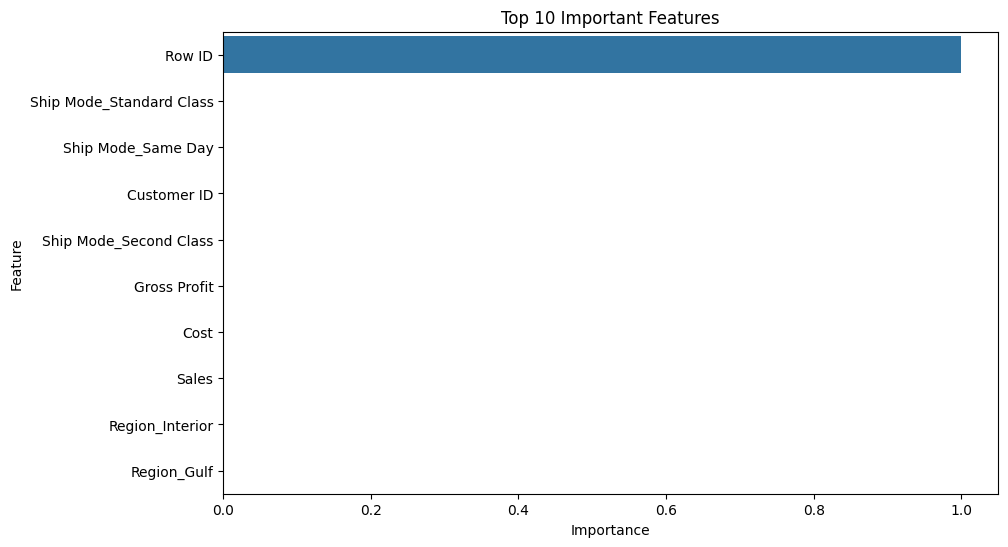

In [115]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10,6))

sns.barplot(
    data=importance.head(10),
    x='Importance',
    y='Feature'
)

plt.title("Top 10 Important Features")

plt.show()

In [116]:
from sklearn.cluster import KMeans

cluster_data = data[
    ['Sales',
     'Units',
     'Gross Profit',
     'Cost']
]

kmeans = KMeans(
    n_clusters=3,
    random_state=42
)

data['Cluster'] = kmeans.fit_predict(cluster_data)

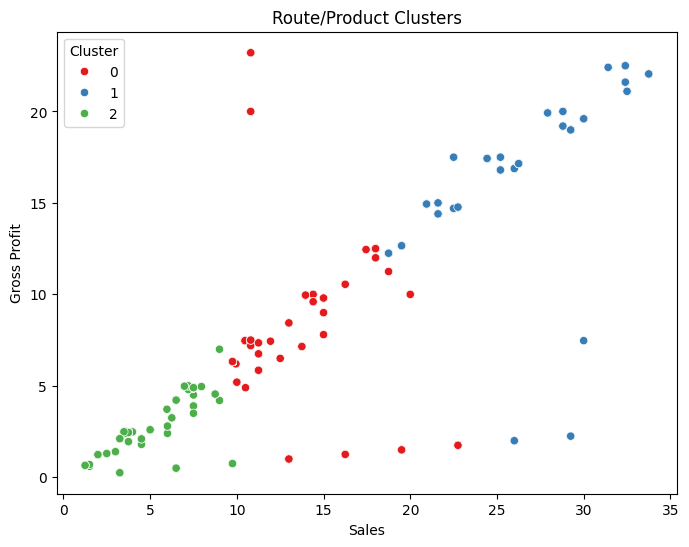

In [117]:
plt.figure(figsize=(8,6))

sns.scatterplot(
    data=data,
    x='Sales',
    y='Gross Profit',
    hue='Cluster',
    palette='Set1'
)

plt.title("Route/Product Clusters")

plt.show()

In [118]:
sample = x_test.iloc[[0]].copy()

sample['Sales'] = sample['Sales'] * 1.10

prediction = rf.predict(sample)

print("Predicted Lead Time:", prediction[0])

Predicted Lead Time: 1269.0


In [119]:
importance.head(10)

,Feature,Importance
0,Row ID,9.999576e-01
7087,Ship Mode_Standard Class,2.357599e-05
7085,Ship Mode_Same Day,4.995708e-06
1,Customer ID,2.016301e-06
7086,Ship Mode_Second Class,1.355546e-06
4,Gross Profit,3.456394e-07
5,Cost,3.285692e-07
2,Sales,2.129206e-07
8322,Region_Interior,1.161477e-07
8321,Region_Gulf,1.114043e-07


In [120]:
data.groupby('Region')['Lead Time'].mean()

,Lead Time
Region,
Atlantic,1322.745144
Gulf,1311.374691
Interior,1323.091221
Pacific,1322.194897


In [121]:
data.groupby('Product Name')['Lead Time'].mean()

,Lead Time
Product Name,
Everlasting Gobstopper,1394.666667
Fizzy Lifting Drinks,1273.500000
Fun Dip,1272.666667
Hair Toffee,1455.250000
Kazookles,1272.989583
Laffy Taffy,1383.100000
Lickable Wallpaper,1339.138298
Nerds,1274.000000
SweeTARTS,1383.500000


In [122]:
data.groupby(['Region','Product Name'])['Lead Time'].mean()

Region    Product Name                     
Atlantic  Fizzy Lifting Drinks                 1455.500000
          Fun Dip                              1275.000000
          Hair Toffee                          1639.000000
          Kazookles                            1273.108108
          Laffy Taffy                          1456.166667
          Lickable Wallpaper                   1387.828571
          Nerds                                1274.000000
          SweeTARTS                            1347.600000
          Wonka Bar - Fudge Mallows            1321.171533
          Wonka Bar - Milk Chocolate           1309.320814
          Wonka Bar - Nutty Crunch Surprise    1360.426531
          Wonka Bar - Triple Dazzle Caramel    1323.578853
          Wonka Bar -Scrumdiddlyumptious       1305.370787
          Wonka Gum                            1312.756757
Gulf      Everlasting Gobstopper               1273.000000
          Fizzy Lifting Drinks                  909.000000
          Fun Dip                              1272.000000
          Hair Toffee                          1635.000000
          Kazookles                            1252.500000
          Laffy Taffy                          1092.000000
          Lickable Wallpaper                   1309.500000
          Wonka Bar - Fudge Mallows            1304.580756
          Wonka Bar - Milk Chocolate           1289.732733
          Wonka Bar - Nutty Crunch Surprise    1322.614865
          Wonka Bar - Triple Dazzle Caramel    1328.669697
          Wonka Bar -Scrumdiddlyumptious       1314.545161
          Wonka Gum                            1343.692308
Interior  Everlasting Gobstopper               1641.000000
          Fizzy Lifting Drinks                 1273.500000
          Fun Dip                              1271.000000
          Kazookles                            1206.636364
          Laffy Taffy                          1272.000000
          Lickable Wallpaper                   1321.466667
          SweeTARTS                            1364.750000
          Wonka Bar - Fudge Mallows            1311.570732
          Wonka Bar - Milk Chocolate           1331.977956
          Wonka Bar - Nutty Crunch Surprise    1329.847345
          Wonka Bar - Triple Dazzle Caramel    1316.334812
          Wonka Bar -Scrumdiddlyumptious       1329.908497
          Wonka Gum                            1260.206897
Pacific   Everlasting Gobstopper               1270.000000
          Fizzy Lifting Drinks                 1274.000000
          Hair Toffee                          1273.500000
          Kazookles                            1309.466667
          Laffy Taffy                          1638.000000
          Lickable Wallpaper                   1305.529412
          SweeTARTS                            1638.000000
          Wonka Bar - Fudge Mallows            1314.434095
          Wonka Bar - Milk Chocolate           1326.024024
          Wonka Bar - Nutty Crunch Surprise    1304.445804
          Wonka Bar - Triple Dazzle Caramel    1332.133136
          Wonka Bar -Scrumdiddlyumptious       1331.282738
          Wonka Gum                            1311.750000
Name: Lead Time, dtype: float64

In [123]:
data['Order Date'] = pd.to_datetime(data['Order Date'], dayfirst=True)
data['Ship Date'] = pd.to_datetime(data['Ship Date'], dayfirst=True)

data['Lead Time'] = (data['Ship Date'] - data['Order Date']).dt.days

In [124]:
region_product = data.groupby(
    ['Region', 'Product Name']
).agg(
    Avg_Lead_Time=('Lead Time', 'mean'),
    Total_Sales=('Sales', 'sum'),
    Total_Units=('Units', 'sum'),
    Total_Profit=('Gross Profit', 'sum')
).reset_index()

region_product.head()

,Region,Product Name,Avg_Lead_Time,Total_Sales,Total_Units,Total_Profit
0,Atlantic,Fizzy Lifting Drinks,1455.500000,33.75,9,20.25
1,Atlantic,Fun Dip,1275.000000,6.00,4,2.40
2,Atlantic,Hair Toffee,1639.000000,22.50,5,17.50
3,Atlantic,Kazookles,1273.108108,484.25,149,37.25
4,Atlantic,Laffy Taffy,1456.166667,27.86,14,17.36


In [125]:
top_congested = region_product.sort_values(
    by='Avg_Lead_Time',
    ascending=False
)

top_congested.head(10)

,Region,Product Name,Avg_Lead_Time,Total_Sales,Total_Units,Total_Profit
27,Interior,Everlasting Gobstopper,1641.000000,30.00,3,7.47
2,Atlantic,Hair Toffee,1639.000000,22.50,5,17.50
44,Pacific,Laffy Taffy,1638.000000,1.99,1,1.24
46,Pacific,SweeTARTS,1638.000000,6.00,4,2.80
17,Gulf,Hair Toffee,1635.000000,9.00,2,7.00
4,Atlantic,Laffy Taffy,1456.166667,27.86,14,17.36
0,Atlantic,Fizzy Lifting Drinks,1455.500000,33.75,9,20.25
5,Atlantic,Lickable Wallpaper,1387.828571,405.60,129,369.28
33,Interior,SweeTARTS,1364.750000,19.50,13,9.10
10,Atlantic,Wonka Bar - Nutty Crunch Surprise,1360.426531,6242.76,1788,4452.12


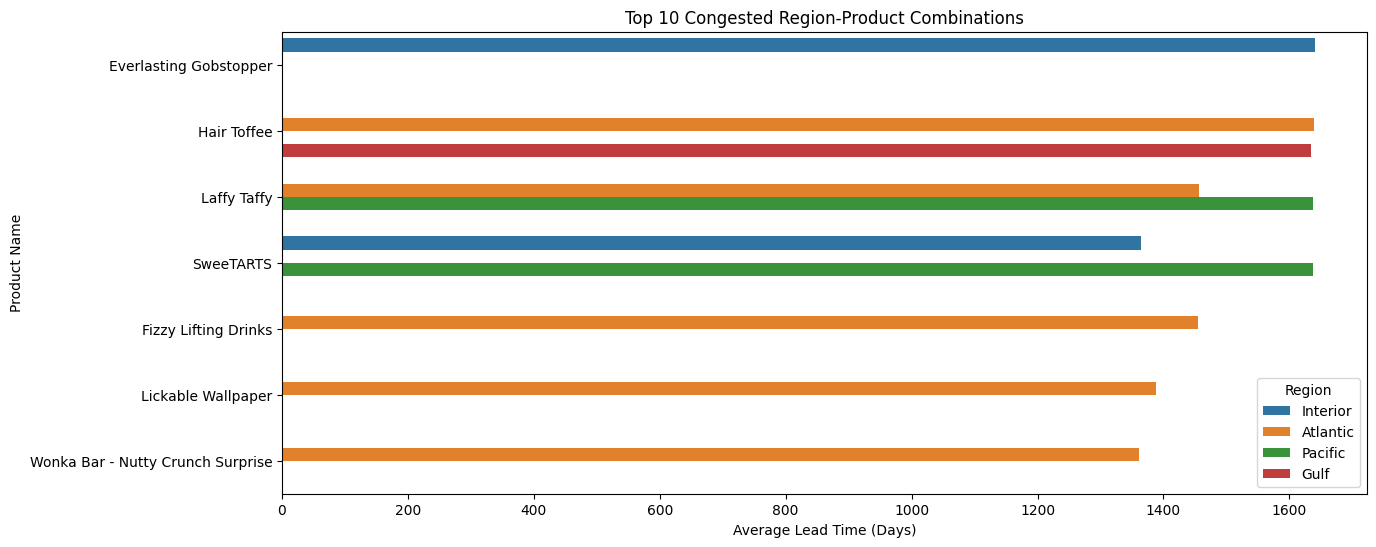

In [126]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14,6))

sns.barplot(
    data=top_congested.head(10),
    x='Avg_Lead_Time',
    y='Product Name',
    hue='Region'
)

plt.title('Top 10 Congested Region-Product Combinations')

plt.xlabel('Average Lead Time (Days)')

plt.ylabel('Product Name')

plt.show()

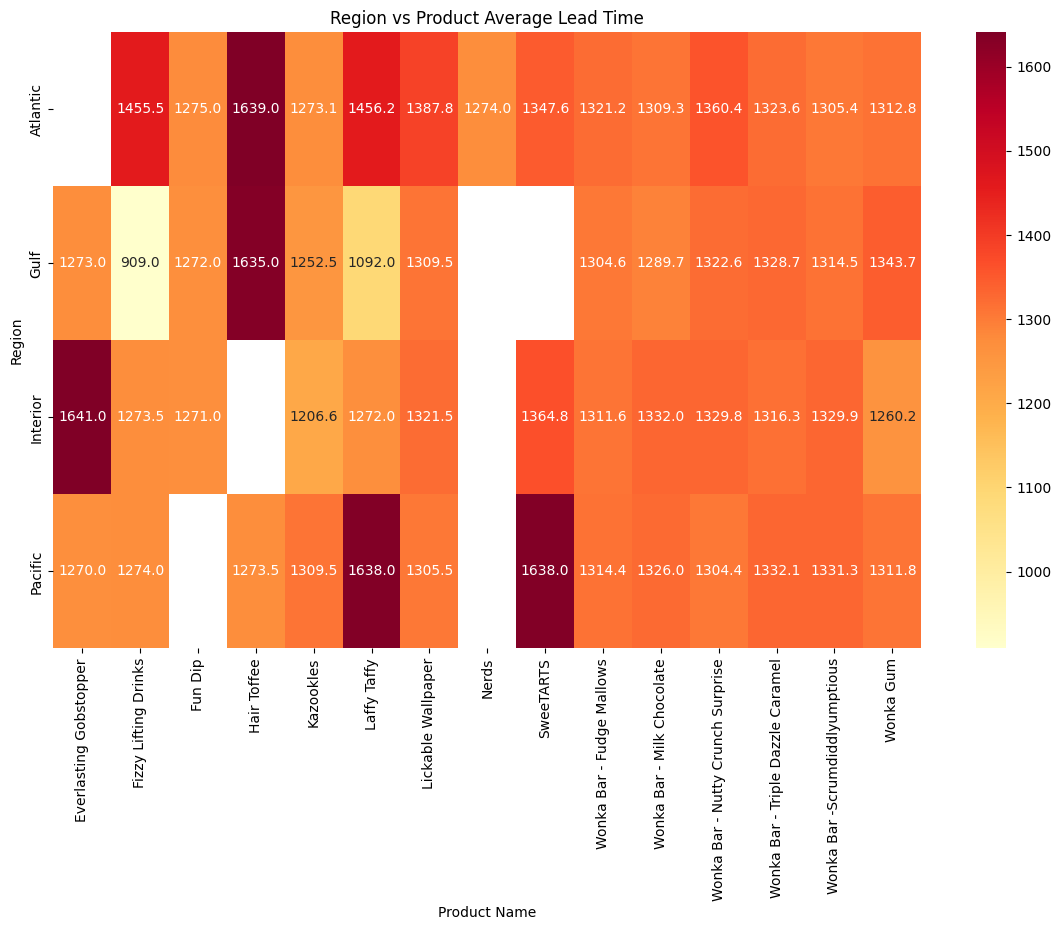

In [127]:
pivot_table = region_product.pivot(
    index='Region',
    columns='Product Name',
    values='Avg_Lead_Time'
)

plt.figure(figsize=(14,8))

sns.heatmap(
    pivot_table,
    annot=True,
    cmap='YlOrRd',
    fmt='.1f'
)

plt.title('Region vs Product Average Lead Time')

plt.show()

In [128]:
region_summary = data.groupby('Region').agg(
    Average_Lead_Time=('Lead Time', 'mean'),
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Gross Profit', 'sum')
)

region_summary

,Average_Lead_Time,Total_Sales,Total_Profit
Region,,,
Atlantic,1322.745144,37498.17,25089.46
Gulf,1311.374691,20776.33,13907.31
Interior,1323.091221,29939.33,20153.35
Pacific,1322.194897,41949.30,28215.15


In [129]:
product_summary = data.groupby('Product Name').agg(
    Average_Lead_Time=('Lead Time', 'mean'),
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Gross Profit', 'sum')
)

product_summary

,Average_Lead_Time,Total_Sales,Total_Profit
Product Name,,,
Everlasting Gobstopper,1394.666667,51.60,22.41
Fizzy Lifting Drinks,1273.500000,78.75,47.25
Fun Dip,1272.666667,12.00,4.80
Hair Toffee,1455.250000,76.50,59.50
Kazookles,1272.989583,1205.75,92.75
Laffy Taffy,1383.100000,53.73,33.48
Lickable Wallpaper,1339.138298,1052.00,1000.49
Nerds,1274.000000,15.00,7.00
SweeTARTS,1383.500000,61.50,28.70


In [130]:
high_risk = region_product[
    region_product['Avg_Lead_Time'] >
    region_product['Avg_Lead_Time'].mean()
]

high_risk

,Region,Product Name,Avg_Lead_Time,Total_Sales,Total_Units,Total_Profit
0,Atlantic,Fizzy Lifting Drinks,1455.500000,33.75,9,20.25
2,Atlantic,Hair Toffee,1639.000000,22.50,5,17.50
4,Atlantic,Laffy Taffy,1456.166667,27.86,14,17.36
5,Atlantic,Lickable Wallpaper,1387.828571,405.60,129,369.28
7,Atlantic,SweeTARTS,1347.600000,36.00,24,16.80
10,Atlantic,Wonka Bar - Nutty Crunch Surprise,1360.426531,6242.76,1788,4452.12
17,Gulf,Hair Toffee,1635.000000,9.00,2,7.00
26,Gulf,Wonka Gum,1343.692308,150.00,105,78.00
27,Interior,Everlasting Gobstopper,1641.000000,30.00,3,7.47
33,Interior,SweeTARTS,1364.750000,19.50,13,9.10


In [131]:
top_congested.to_csv(
    'Top_Congested_Region_Product.csv',
    index=False
)

print("File Saved Successfully")

File Saved Successfully


In [132]:
import numpy as np

np.random.seed(42)

factories = [
    'Factory A',
    'Factory B',
    'Factory C'
]

data['Factory'] = np.random.choice(
    factories,
    size=len(data)
)

data[['Product Name','Factory']].head()

,Product Name,Factory
0,Wonka Bar - Milk Chocolate,Factory C
1,Wonka Bar - Triple Dazzle Caramel,Factory A
2,Wonka Bar - Nutty Crunch Surprise,Factory C
3,Wonka Bar -Scrumdiddlyumptious,Factory C
4,Wonka Bar - Triple Dazzle Caramel,Factory A


In [133]:
data['Factory'].value_counts()

,count
Factory,
Factory A,3423
Factory B,3419
Factory C,3352


In [134]:
simulation = data.copy()

factory_mapping = {
    'Factory A':'Factory B',
    'Factory B':'Factory C',
    'Factory C':'Factory A'
}

simulation['Recommended Factory'] = simulation['Factory'].map(factory_mapping)

simulation[
    ['Product Name',
     'Factory',
     'Recommended Factory']
].head()

,Product Name,Factory,Recommended Factory
0,Wonka Bar - Milk Chocolate,Factory C,Factory A
1,Wonka Bar - Triple Dazzle Caramel,Factory A,Factory B
2,Wonka Bar - Nutty Crunch Surprise,Factory C,Factory A
3,Wonka Bar -Scrumdiddlyumptious,Factory C,Factory A
4,Wonka Bar - Triple Dazzle Caramel,Factory A,Factory B


In [135]:
simulation_encoded = pd.get_dummies(
    simulation.drop(
        ['Lead Time'],
        axis=1
    ),
    drop_first=True
)

simulation_encoded = simulation_encoded.reindex(
    columns=x_train.columns,
    fill_value=0
)

simulation_scaled = sc.transform(simulation_encoded)

simulation['Predicted Lead Time'] = rf.predict(simulation_scaled)

In [136]:
simulation['Improved Lead Time'] = (
    simulation['Predicted Lead Time'] * 0.90
)

In [137]:
simulation['Lead Time Reduction'] = (
    simulation['Predicted Lead Time']
    -
    simulation['Improved Lead Time']
)

In [138]:
simulation['Lead Time Reduction %'] = (
    simulation['Lead Time Reduction']
    /
    simulation['Predicted Lead Time']
) * 100

In [139]:
simulation['Estimated Profit'] = (
    simulation['Gross Profit']
    *
    (
        1 +
        simulation['Lead Time Reduction'] * 0.02
    )
)

In [140]:
simulation['Profit Improvement'] = (
    simulation['Estimated Profit']
    -
    simulation['Gross Profit']
)

In [141]:
simulation[
[
'Product Name',
'Factory',
'Recommended Factory',
'Predicted Lead Time',
'Improved Lead Time',
'Lead Time Reduction',
'Profit Improvement'
]
].head(20)

,Product Name,Factory,Recommended Factory,Predicted Lead Time,Improved Lead Time,Lead Time Reduction,Profit Improvement
0,Wonka Bar - Milk Chocolate,Factory C,Factory A,909.425,818.4825,90.9425,7.675547
1,Wonka Bar - Triple Dazzle Caramel,Factory A,Factory B,909.155,818.2395,90.9155,8.909719
2,Wonka Bar - Nutty Crunch Surprise,Factory C,Factory A,909.210,818.2890,90.9210,13.583597
3,Wonka Bar -Scrumdiddlyumptious,Factory C,Factory A,909.270,818.3430,90.9270,13.639050
4,Wonka Bar - Triple Dazzle Caramel,Factory A,Factory B,910.800,819.7200,91.0800,13.388760
5,Wonka Bar -Scrumdiddlyumptious,Factory A,Factory B,909.130,818.2170,90.9130,40.910850
6,Wonka Bar - Triple Dazzle Caramel,Factory C,Factory A,909.055,818.1495,90.9055,8.908739
7,Wonka Bar - Milk Chocolate,Factory B,Factory C,906.110,815.4990,90.6110,11.471353
8,Wonka Bar - Nutty Crunch Surprise,Factory C,Factory A,909.095,818.1855,90.9095,9.054586
9,Wonka Bar - Milk Chocolate,Factory C,Factory A,909.215,818.2935,90.9215,15.347549


In [142]:
recommendation = simulation.sort_values(
    by='Lead Time Reduction',
    ascending=False
)

recommendation.head(10)

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Country/Region,City,State/Province,Postal Code,...,Lead Time,Cluster,Factory,Recommended Factory,Predicted Lead Time,Improved Lead Time,Lead Time Reduction,Lead Time Reduction %,Estimated Profit,Profit Improvement
7800,7801,US-2024-140872-CHO-MIL-31000,2025-06-03,2029-12-01,Standard Class,140872,United States,Pembroke Pines,Florida,33024,...,1642,2,Factory B,Factory C,1642.000,1477.8000,164.2000,10.0,18.078480,13.858480
7796,7797,US-2024-140872-CHO-FUD-51000,2025-06-03,2029-12-01,Standard Class,140872,United States,Pembroke Pines,Florida,33024,...,1642,2,Factory C,Factory A,1641.970,1477.7730,164.1970,10.0,20.562912,15.762912
7809,7810,US-2024-140872-CHO-FUD-51000,2025-06-03,2029-12-01,Standard Class,140872,United States,Pembroke Pines,Florida,33024,...,1642,2,Factory B,Factory C,1641.965,1477.7685,164.1965,10.0,10.281432,7.881432
7812,7813,US-2024-140872-CHO-MIL-31000,2025-06-03,2029-12-01,Standard Class,140872,United States,Pembroke Pines,Florida,33024,...,1642,0,Factory B,Factory C,1641.960,1477.7640,164.1960,10.0,45.195356,34.645356
7802,7803,US-2024-140872-CHO-TRI-54000,2025-06-03,2029-12-01,Standard Class,140872,United States,Pembroke Pines,Florida,33024,...,1642,0,Factory C,Factory A,1641.950,1477.7550,164.1950,10.0,31.486665,24.136665
7803,7804,US-2024-140872-CHO-TRI-54000,2025-06-03,2029-12-01,Standard Class,140872,United States,Pembroke Pines,Florida,33024,...,1642,0,Factory B,Factory C,1641.950,1477.7550,164.1950,10.0,31.486665,24.136665
7799,7800,US-2024-140872-CHO-TRI-54000,2025-06-03,2029-12-01,Standard Class,140872,United States,Pembroke Pines,Florida,33024,...,1642,1,Factory C,Factory A,1641.910,1477.7190,164.1910,10.0,73.467513,56.317513
7807,7808,US-2024-140872-CHO-NUT-13000,2025-06-03,2029-12-01,Standard Class,140872,United States,Pembroke Pines,Florida,33024,...,1642,2,Factory A,Factory B,1641.895,1477.7055,164.1895,10.0,21.333274,16.353274
8350,8351,US-2024-166093-CHO-SCR-58000,2025-08-17,2030-02-14,Standard Class,166093,United States,Brentwood,California,94513,...,1642,1,Factory B,Factory C,1641.890,1477.7010,164.1890,10.0,96.385050,73.885050
8356,8357,US-2024-166093-CHO-TRI-54000,2025-08-17,2030-02-14,Standard Class,166093,United States,Brentwood,California,94513,...,1642,1,Factory C,Factory A,1641.885,1477.6965,164.1885,10.0,83.961892,64.361892


In [143]:
recommendation.to_csv(
    "Factory_Recommendations.csv",
    index=False
)

In [144]:
product_summary = data.groupby(
    ['Product Name', 'Region']
).agg(
    Avg_Lead_Time=('Lead Time', 'mean'),
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Gross Profit', 'sum'),
    Total_Cost=('Cost', 'sum')
).reset_index()

product_summary.head()

,Product Name,Region,Avg_Lead_Time,Total_Sales,Total_Profit,Total_Cost
0,Everlasting Gobstopper,Gulf,1273.0,10.80,7.47,8.0
1,Everlasting Gobstopper,Interior,1641.0,30.00,7.47,6.0
2,Everlasting Gobstopper,Pacific,1270.0,10.80,7.47,3.6
3,Fizzy Lifting Drinks,Atlantic,1455.5,33.75,20.25,13.5
4,Fizzy Lifting Drinks,Gulf,909.0,15.00,9.00,6.0


In [145]:
product_summary['Risk Score'] = (
    product_summary['Avg_Lead_Time'] /
    product_summary['Avg_Lead_Time'].max()
)

In [146]:
product_summary['Profit Impact'] = (
    product_summary['Total_Profit'] /
    product_summary['Total_Profit'].max()
)

In [147]:
product_summary['Efficiency Score'] = (
    product_summary['Profit Impact']
    -
    product_summary['Risk Score']
)

In [148]:
recommendation = product_summary.sort_values(
    by='Efficiency Score',
    ascending=False
)

recommendation.head(10)

,Product Name,Region,Avg_Lead_Time,Total_Sales,Total_Profit,Total_Cost,Risk Score,Profit Impact,Efficiency Score
44,Wonka Bar - Triple Dazzle Caramel,Pacific,1332.133136,9430.50,6165.40,3105.80,0.811781,1.000000,0.188219
48,Wonka Bar -Scrumdiddlyumptious,Pacific,1331.282738,8524.80,5919.64,2608.40,0.811263,0.960139,0.148876
45,Wonka Bar -Scrumdiddlyumptious,Atlantic,1305.370787,8028.00,5574.58,2457.20,0.795473,0.904172,0.108699
36,Wonka Bar - Milk Chocolate,Pacific,1326.024024,8363.95,5452.29,2899.98,0.808059,0.884337,0.076278
40,Wonka Bar - Nutty Crunch Surprise,Pacific,1304.445804,7132.71,5087.07,2054.20,0.794909,0.825100,0.030191
32,Wonka Bar - Fudge Mallows,Pacific,1314.434095,7617.60,5081.91,2402.40,0.800996,0.824263,0.023267
41,Wonka Bar - Triple Dazzle Caramel,Atlantic,1323.578853,7617.30,4979.12,2502.10,0.806568,0.807591,0.001022
33,Wonka Bar - Milk Chocolate,Atlantic,1309.320814,7416.30,4849.12,2545.68,0.797880,0.786505,-0.011375
29,Wonka Bar - Fudge Mallows,Atlantic,1321.171533,6951.60,4636.83,2223.60,0.805101,0.752073,-0.053029
37,Wonka Bar - Nutty Crunch Surprise,Atlantic,1360.426531,6242.76,4452.12,1818.40,0.829023,0.722114,-0.106909


In [149]:
top10 = recommendation[
    [
        'Product Name',
        'Region',
        'Avg_Lead_Time',
        'Total_Profit',
        'Efficiency Score'
    ]
]

top10.head(10)

,Product Name,Region,Avg_Lead_Time,Total_Profit,Efficiency Score
44,Wonka Bar - Triple Dazzle Caramel,Pacific,1332.133136,6165.40,0.188219
48,Wonka Bar -Scrumdiddlyumptious,Pacific,1331.282738,5919.64,0.148876
45,Wonka Bar -Scrumdiddlyumptious,Atlantic,1305.370787,5574.58,0.108699
36,Wonka Bar - Milk Chocolate,Pacific,1326.024024,5452.29,0.076278
40,Wonka Bar - Nutty Crunch Surprise,Pacific,1304.445804,5087.07,0.030191
32,Wonka Bar - Fudge Mallows,Pacific,1314.434095,5081.91,0.023267
41,Wonka Bar - Triple Dazzle Caramel,Atlantic,1323.578853,4979.12,0.001022
33,Wonka Bar - Milk Chocolate,Atlantic,1309.320814,4849.12,-0.011375
29,Wonka Bar - Fudge Mallows,Atlantic,1321.171533,4636.83,-0.053029
37,Wonka Bar - Nutty Crunch Surprise,Atlantic,1360.426531,4452.12,-0.106909


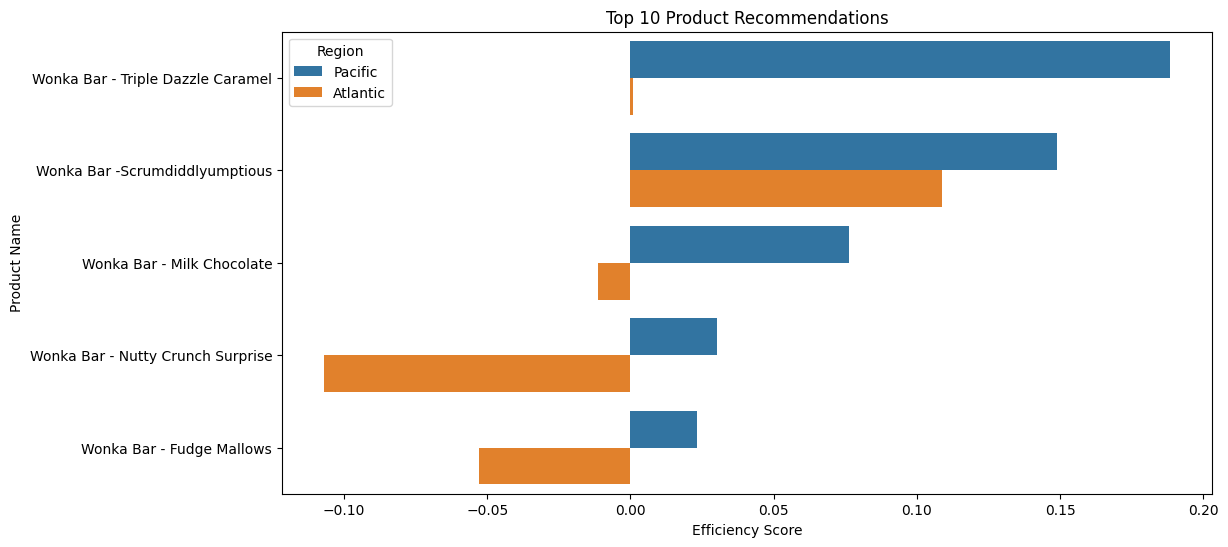

In [150]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12,6))

sns.barplot(
    data=top10.head(10),
    x='Efficiency Score',
    y='Product Name',
    hue='Region'
)

plt.title("Top 10 Product Recommendations")

plt.show()

In [151]:
top10.to_csv(
    "Top_Product_Recommendations.csv",
    index=False
)

# Streamlit Web Application

In [152]:
import pickle

In [153]:
import joblib

joblib.dump(model, "Nassau_Candy_Distributor_model.pkl")
joblib.dump(tfidf, "tfidf_vectorizer.pkl")

print("Files saved!")

NameError: name 'model' is not defined